# 6.5 Klasifikasi Khusus Wonoayu: Sawah vs Non-Sawah

Berbeda dari 6.1–6.4 (6 kelas se-Jatim), bagian ini **biner dan lokal**: 87 poligon digitasi Wonoayu (46 sawah + 41 non-sawah) + raster Sentinel-2A yang **sudah ada** (`jatim/raster/s2_demo_sidoarjo.tif` mencakup Wonoayu penuh). Tanpa download baru.

**Data yang dipakai (semua sudah ada di repo):**

- `sawah.shp` (46 poligon, EPSG:4326) + `data1kelas/input.shp` (sumber, kolom `Sawah`) → label 1.
- `nonsawah.shp` (41 poligon) → label 0.
- Raster demo Sidoarjo–Surabaya @20 m (6 band) → fitur.

**Pembersihan:** 1 geometri sawah invalid → `make_valid`; 2 poligon sawah sedikit keluar tepi barat raster (±500 m) → tetap dipakai (zonal mean dari piksel yang overlap).

In [1]:
import os
import geopandas as gpd
import pandas as pd
from shapely.validation import make_valid

SEED = 42
MODEL_DIR = "jatim/model"
IMG_DIR = "jatim/gambar"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

sw = gpd.read_file("sawah.shp")
ns = gpd.read_file("nonsawah.shp")
sw["kelas"] = 1
ns["kelas"] = 0
g = pd.concat([sw[["kelas", "geometry"]], ns[["kelas", "geometry"]]], ignore_index=True)
g = gpd.GeoDataFrame(g, crs="EPSG:4326")
g["geometry"] = g.geometry.apply(lambda x: make_valid(x) if not x.is_valid else x)
print("total:", len(g), "| sawah:", int((g.kelas == 1).sum()), "| non-sawah:", int((g.kelas == 0).sum()))
print("invalid sisa:", int((~g.geometry.is_valid).sum()))
g32749 = g.to_crs("EPSG:32749")

total: 87 | sawah: 46 | non-sawah: 41
invalid sisa: 0


## Ekstraksi fitur zonal (lokal, dari raster yang sudah ada)

In [2]:
import numpy as np
import rasterio
from rasterio.mask import mask

BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]
src = rasterio.open("jatim/raster/s2_demo_sidoarjo.tif")
nodata = src.nodata
rows = []
for _, r in g32749.iterrows():
    img, _ = mask(src, [r.geometry], crop=True, nodata=nodata)
    img = img.astype(float)
    img[img == nodata] = np.nan
    means = [float(np.nanmean(img[b])) for b in range(src.count)]
    rows.append({"kelas": r["kelas"], **{f"mean_{bnd}": v for bnd, v in zip(BANDS, means)}})
src.close()
df = pd.DataFrame(rows).dropna().reset_index(drop=True)
print("sampel bersih:", len(df), "| sawah:", int((df.kelas == 1).sum()), "| non-sawah:", int((df.kelas == 0).sum()))
B02, B03, B04, B08, B11, B12 = (df[f"mean_{c}"] for c in BANDS)
df["NDVI"] = (B08 - B04) / (B08 + B04)
df["NDWI"] = (B03 - B08) / (B03 + B08)
df["NDBI"] = (B11 - B08) / (B11 + B08)
print(df.groupby("kelas")[["NDVI", "NDWI", "NDBI"]].mean().round(3).to_string())

sampel bersih: 87 | sawah: 46 | non-sawah: 41
        NDVI   NDWI   NDBI
kelas                     
0      0.223 -0.263  0.083
1      0.512 -0.483 -0.131


## Training biner + banding model

In [3]:
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

FEATS = [c for c in df.columns if c != "kelas"]
X = df[FEATS].to_numpy()
y = df["kelas"].to_numpy().astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print("train:", len(Xtr), "test:", len(Xte))
cands = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN-7": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, random_state=SEED)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows, fitted = [], {}
for nama, clf in cands.items():
    clf.fit(Xtr, ytr)
    s = cross_val_score(clf, X, y, cv=cv)
    acc = accuracy_score(yte, clf.predict(Xte))
    rows.append({"model": nama, "accuracy": acc, "cv5_mean": float(s.mean())})
    fitted[nama] = clf
    print(f"{nama}: test={acc:.4f} cv5={float(s.mean()):.4f}")
res = pd.DataFrame(rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
best = res.loc[0, "model"]
print("\nMODEL TERBAIK:", best)
joblib.dump(fitted[best], f"{MODEL_DIR}/wonoayu_best.joblib")
res.to_csv(f"{MODEL_DIR}/wonoayu_model_compare.csv", index=False)
pb = fitted[best].predict(Xte)
print(confusion_matrix(yte, pb))
print(classification_report(yte, pb, target_names=["non-sawah", "sawah"]))

train: 65 test: 22


LogReg: test=0.9545 cv5=0.9778
KNN-7: test=1.0000 cv5=0.9778


RandomForest: test=0.9545 cv5=0.9778
SVM-RBF: test=1.0000 cv5=0.9771

MODEL TERBAIK: KNN-7


[[10  0]
 [ 0 12]]
              precision    recall  f1-score   support

   non-sawah       1.00      1.00      1.00        10
       sawah       1.00      1.00      1.00        12

    accuracy                           1.00        22
   macro avg       1.00      1.00      1.00        22
weighted avg       1.00      1.00      1.00        22



## Peta Folium Wonoayu: Google Satellite + hasil + poligon sampel

Area dipotong ke bbox Wonoayu (±8×6,5 km → ~130 rb piksel, prediksi hitungan detik), overlay di atas Google Satellite, poligon sampel kuning.

piksel valid: 117410 | sawah: 68.8%


tersimpan: jatim/model/wonoayu_classified.tif + jatim/gambar/wonoayu_preview.png + jatim/folium_wonoayu.html



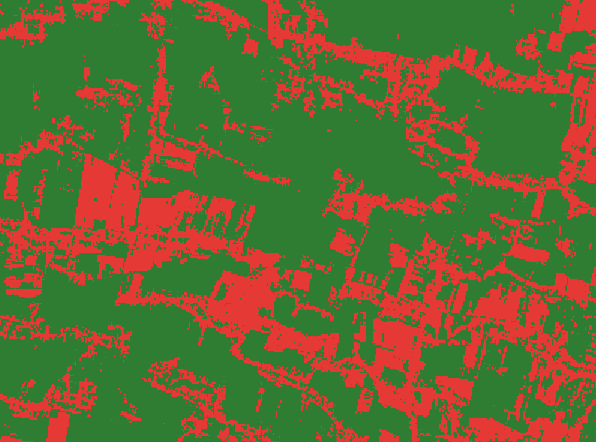

In [4]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import folium
import joblib
import rasterio
from rasterio.windows import from_bounds

OUT_TIF = f"{MODEL_DIR}/wonoayu_classified.tif"
OUT_PNG = f"{IMG_DIR}/wonoayu_preview.png"
OUT_HTML = "jatim/folium_wonoayu.html"
WB = g32749.total_bounds  # minx, miny, maxx, maxy (meter)

clf = joblib.load(f"{MODEL_DIR}/wonoayu_best.joblib")
src = rasterio.open("jatim/raster/s2_demo_sidoarjo.tif")
win = from_bounds(WB[0] - 200, WB[1] - 200, WB[2] + 200, WB[3] + 200, src.transform)
arr = src.read(window=win).astype(float)
nodata = src.nodata
tr = src.window_transform(win)
h, w = arr.shape[1], arr.shape[2]
B02, B03, B04, B08, B11, B12 = arr
with np.errstate(divide="ignore", invalid="ignore"):
    vals = {"mean_B02": B02, "mean_B03": B03, "mean_B04": B04,
            "mean_B08": B08, "mean_B11": B11, "mean_B12": B12,
            "NDVI": (B08 - B04) / (B08 + B04), "NDWI": (B03 - B08) / (B03 + B08),
            "NDBI": (B11 - B08) / (B11 + B08), "NDMI": (B08 - B11) / (B08 + B11),
            "EVI": 2.5 * (B08 - B04) / (B08 + 6 * B04 - 7.5 * B02 + 1),
            "SAVI": ((B08 - B04) / (B08 + B04 + 0.5)) * 1.5}
    flat = np.stack([vals[c] for c in FEATS], axis=0).reshape(len(FEATS), -1).T
ok = np.isfinite(flat).all(axis=1)
if nodata is not None:
    ok &= ~(arr.reshape(6, -1).T == nodata).any(axis=1)
out = np.full(flat.shape[0], 255, dtype=np.uint8)
out[ok] = clf.predict(flat[ok]).astype(np.uint8)
print(f"piksel valid: {int(ok.sum())} | sawah: {float((out[ok] == 1).mean()) * 100:.1f}%")
meta = src.meta.copy()
meta.update(count=1, dtype="uint8", nodata=255, transform=tr, width=w, height=h)
with rasterio.open(OUT_TIF, "w", **meta) as dst:
    dst.write(out.reshape(h, w), 1)
src.close()
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(np.ma.masked_equal(out.reshape(h, w), 255), vmin=0, vmax=1,
          cmap=ListedColormap(["#e53935", "#2e7d32"]), interpolation="nearest")
ax.axis("off")
fig.savefig(OUT_PNG, dpi=110, bbox_inches="tight", pad_inches=0)
plt.close(fig)
s, wlon = WB[1], WB[0]
gw = g.to_crs("EPSG:4326").total_bounds
m = folium.Map(location=[(gw[1] + gw[3]) / 2, (gw[0] + gw[2]) / 2], zoom_start=14,
               tiles=None, control_scale=True)
folium.TileLayer(tiles="https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",
                 attr="Google Satellite", name="Google Satellite", overlay=False, max_zoom=20).add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", overlay=False).add_to(m)
folium.raster_layers.ImageOverlay(OUT_PNG, bounds=[[gw[1], gw[0]], [gw[3], gw[2]]],
                                  name="Hasil: hijau=sawah, merah=non-sawah", opacity=0.6).add_to(m)
for kl, nama, col in [(1, "Sawah", "lime"), (0, "Non-sawah", "red")]:
    fg = folium.FeatureGroup(name=f"Sampel {nama}")
    for _, r in g[g.kelas == kl].iterrows():
        gj = gpd.GeoSeries([r.geometry], crs="EPSG:4326").to_json()
        folium.GeoJson(gj, style_function=lambda _, c=col: {"color": c, "weight": 2, "fillOpacity": 0},
                       tooltip=nama).add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(OUT_HTML)
print("tersimpan:", OUT_TIF, "+", OUT_PNG, "+", OUT_HTML)
m